In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [11]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)

In [12]:
df = pd.read_csv('Instagram_fake_profile_dataset (1).csv')

print("--- 5 سطر اول (Head) ---")
display(df.head())

print("\n--- 5 سطر آخر (Tail) ---")
display(df.tail())

print("\n--- ابعاد دیتاست (Shape) ---")
print(f"تعداد سطرها: {df.shape[0]} | تعداد ستون‌ها: {df.shape[1]}")

print("\n--- اطلاعات ستون‌ها (Info) ---")
df.info()

print("\n--- آمار توصیفی (Describe) ---")
display(df.describe())

print("\n--- بررسی مقادیر خالی در هر ستون ---")
print(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print(f"\nتعداد سطرهای تکراری: {duplicate_count}")


--- 5 سطر اول (Head) ---


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
0,1,0.27,0,0.0,0,53,0,0,32,1000,955,0
1,1,0.00,2,0.0,0,44,0,0,286,2740,533,0
2,1,0.10,2,0.0,0,0,0,1,13,159,98,0
3,1,0.00,1,0.0,0,82,0,0,679,414,651,0
4,1,0.00,2,0.0,0,0,0,1,6,151,126,0



--- 5 سطر آخر (Tail) ---


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
4995,0,0.258135,0,0.000000,0,0,0,1,7,1,217,1
4996,0,0.511986,1,0.000000,0,0,0,0,0,51,24,1
4997,0,0.473108,1,0.353231,0,0,0,0,0,20,0,1
4998,0,0.293326,1,0.000000,0,0,0,0,75,1314,5120,1
4999,0,0.605471,1,0.016533,0,1,0,0,0,57,344,1



--- ابعاد دیتاست (Shape) ---
تعداد سطرها: 5000 | تعداد ستون‌ها: 12

--- اطلاعات ستون‌ها (Info) ---
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   profile pic           5000 non-null   int64  
 1   nums/length username  5000 non-null   float64
 2   fullname words        5000 non-null   int64  
 3   nums/length fullname  5000 non-null   float64
 4   name==username        5000 non-null   int64  
 5   description length    5000 non-null   int64  
 6   external URL          5000 non-null   int64  
 7   private               5000 non-null   int64  
 8   #posts                5000 non-null   int64  
 9   #followers            5000 non-null   int64  
 10  #follows              5000 non-null   int64  
 11  fake                  5000 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 468.9 KB

--- آمار توصیفی (Describe) ---


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.00000
mean,0.598200,0.166175,1.212800,0.036068,0.007600,20.997200,0.049600,0.227800,103.331400,5.124435e+04,481.381800,0.50000
std,0.490311,0.194733,0.890435,0.106235,0.086855,33.234706,0.217139,0.419455,377.804886,5.963749e+05,761.530132,0.50005
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.00000
25%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000e+01,58.000000,0.00000
50%,1.000000,0.089193,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,10.000000,1.450000e+02,242.000000,0.50000
75%,1.000000,0.300410,2.000000,0.000000,0.000000,31.250000,0.000000,0.000000,81.000000,6.960000e+02,591.000000,1.00000
max,1.000000,0.920000,12.000000,1.000000,1.000000,150.000000,1.000000,1.000000,7389.000000,1.533854e+07,7500.000000,1.00000



--- بررسی مقادیر خالی در هر ستون ---
profile pic             0
nums/length username    0
fullname words          0
nums/length fullname    0
name==username          0
description length      0
external URL            0
private                 0
#posts                  0
#followers              0
#follows                0
fake                    0
dtype: int64

تعداد سطرهای تکراری: 66


In [13]:
if duplicate_count > 0:
    df = df.drop_duplicates()
    print(f"سطرهای تکراری حذف شدند. ابعاد جدید: {df.shape}")
else:
    print("هیچ سطر تکراری برای حذف وجود ندارد.")

if df.isnull().sum().sum() > 0:
    df = df.dropna()
    print("سطرهای حاوی مقادیر خالی حذف شدند.")
else:
    print("دیتاست فاقد مقادیر خالی (Missing Values) است.")

print("\nنوع داده‌های ستون‌ها پس از بررسی:")
print(df.dtypes)


سطرهای تکراری حذف شدند. ابعاد جدید: (4934, 12)
دیتاست فاقد مقادیر خالی (Missing Values) است.

نوع داده‌های ستون‌ها پس از بررسی:
profile pic               int64
nums/length username    float64
fullname words            int64
nums/length fullname    float64
name==username            int64
description length        int64
external URL              int64
private                   int64
#posts                    int64
#followers                int64
#follows                  int64
fake                      int64
dtype: object


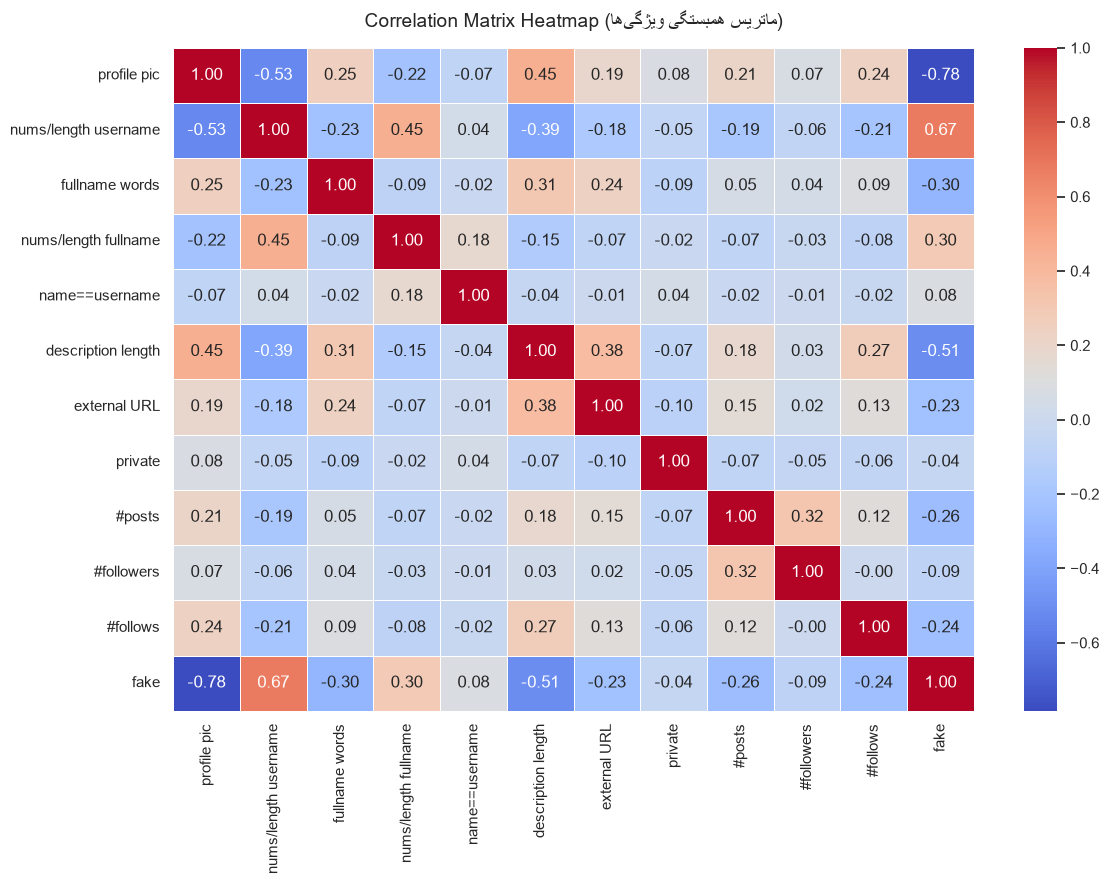

In [14]:
corr_matrix = df.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    linewidths=0.5,
    cbar=True
)
plt.title("Correlation Matrix Heatmap (ماتریس همبستگی ویژگی‌ها)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [15]:
X = df.drop(columns=['fake'])
y = df['fake']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y 
)

print(f"تعداد داده‌های آموزش (Train): {X_train.shape[0]}")
print(f"تعداد داده‌های تست (Test): {X_test.shape[0]}")

تعداد داده‌های آموزش (Train): 3947
تعداد داده‌های تست (Test): 987


In [16]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)


y_pred_dt = dt_model.predict(X_test)



rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)


y_pred_rf = rf_model.predict(X_test)

In [17]:
metrics = {
    'Metric': ['Accuracy (دقت کلی)', 'Precision (صحت)', 'Recall (حساسیت)', 'F1-Score'],
    'Decision Tree': [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ]
}

comparison_df = pd.DataFrame(metrics)
display(comparison_df.round(4))

print("=" * 60)
print("Classification Report - Decision Tree:")
print(classification_report(y_test, y_pred_dt, target_names=['Real (0)', 'Fake (1)']))

print("=" * 60)
print("Classification Report - Random Forest:")
print(classification_report(y_test, y_pred_rf, target_names=['Real (0)', 'Fake (1)']))


,Metric,Decision Tree,Random Forest
0,Accuracy (دقت کلی),0.9777,0.9838
1,Precision (صحت),0.9796,0.9917
2,Recall (حساسیت),0.9756,0.9756
3,F1-Score,0.9776,0.9836


Classification Report - Decision Tree:
              precision    recall  f1-score   support

    Real (0)       0.98      0.98      0.98       495
    Fake (1)       0.98      0.98      0.98       492

    accuracy                           0.98       987
   macro avg       0.98      0.98      0.98       987
weighted avg       0.98      0.98      0.98       987

Classification Report - Random Forest:
              precision    recall  f1-score   support

    Real (0)       0.98      0.99      0.98       495
    Fake (1)       0.99      0.98      0.98       492

    accuracy                           0.98       987
   macro avg       0.98      0.98      0.98       987
weighted avg       0.98      0.98      0.98       987



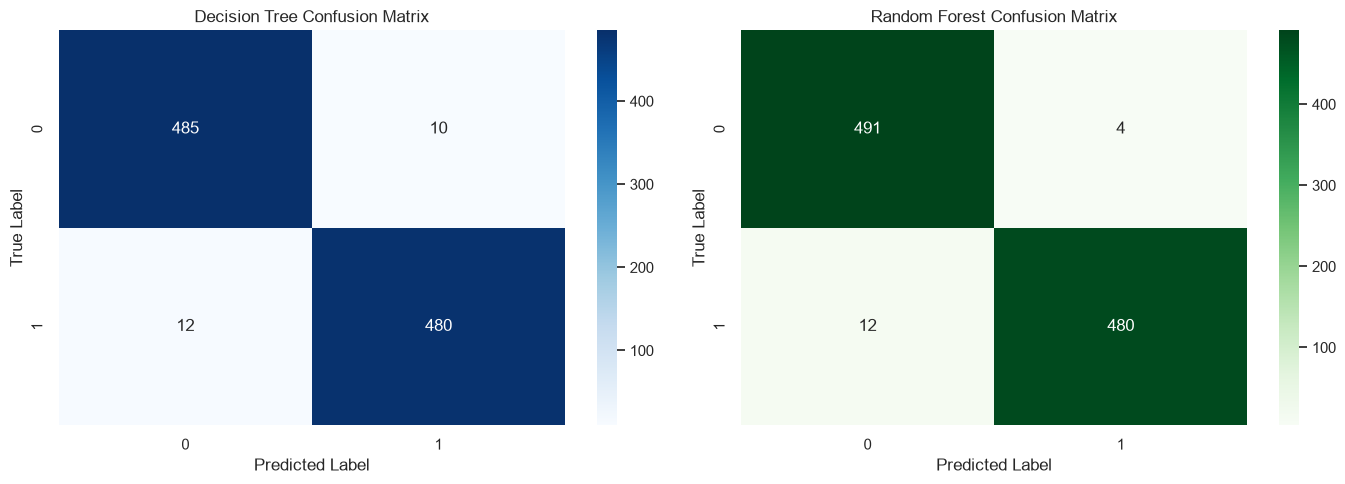

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Decision Tree Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')


sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()
